# Cooling coffee

A cup of filter coffee, a kitchen at 22 °C, and a thermometer read every two minutes. How long until it is pleasant to drink?

## The model

Newton's law of cooling says the cup loses heat in proportion to how much warmer it is than the room:

$$\frac{dT}{dt} = -k\,(T - T_{\text{room}})$$

which solves to $T(t) = T_{\text{room}} + (T_0 - T_{\text{room}})\,e^{-kt}$. One number, $k$, describes the cup.

In [1]:
import numpy as np
import pandas as pd

room = 22.0
minutes = np.arange(0, 32, 2)
rng = np.random.default_rng(7)
temp = room + (88 - room) * np.exp(-0.047 * minutes) + rng.normal(0, 0.4, minutes.size)

readings = pd.DataFrame({"minute": minutes, "temp_c": temp.round(1)})
readings.head(6)

,minute,temp_c
0,0,88.0
1,2,82.2
2,4,76.6
3,6,71.4
4,8,67.1
5,10,62.9


## Fitting k

Taking the log of the excess temperature turns the curve into a straight line, so a plain least squares fit is enough.

In [2]:
excess = np.log(readings.temp_c - room)
slope, intercept = np.polyfit(readings.minute, excess, 1)
k = -slope

print(f"k = {k:.4f} per minute")
print(f"half the excess heat is gone every {np.log(2) / k:.1f} minutes")

k = 0.0468 per minute
half the excess heat is gone every 14.8 minutes


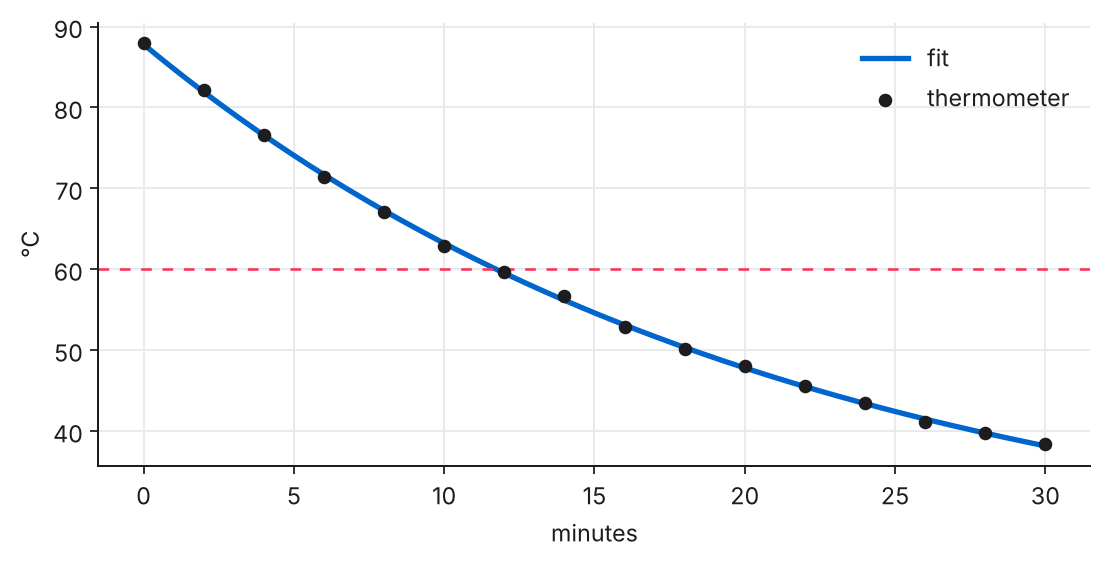

In [3]:
t = np.linspace(0, 30, 200)
fit = room + np.exp(intercept) * np.exp(-k * t)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(t, fit, color="#0066cc", lw=2.4, label="fit")
ax.scatter(readings.minute, readings.temp_c, s=26, color="#1d1d1f", zorder=3, label="thermometer")
ax.axhline(60, color="#ff375f", lw=1.2, ls=(0, (4, 4)))
ax.set(xlabel="minutes", ylabel="°C")
ax.legend(frameon=False)

## When to drink

Most people stop flinching at 60 °C.

In [4]:
drinkable = np.log((88 - room) / (60 - room)) / k
print(f"Drinkable after {drinkable:.1f} minutes.")

Drinkable after 11.8 minutes.
